In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rainfall = pd.read_csv("../data/raw/rainfall_original.csv")

print("Dataset shape:", rainfall.shape)
print("\nColumn names:")
print(rainfall.columns.tolist())

print("\nFirst five rows:")
display(rainfall.head())

print("\nData types:")
rainfall.info()

print("\nMissing values:")
print(rainfall.isnull().sum())

Dataset shape: (4188, 19)

Column names:
['SUBDIVISION', 'YEAR', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC', 'ANNUAL', 'JF', 'MAM', 'JJAS', 'OND']

First five rows:


,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JF,MAM,JJAS,OND
0,Andaman & Nicobar Islands,1901,49.2,87.1,29.2,2.3,528.8,517.5,365.1,481.1,332.6,388.5,558.2,33.6,3373.2,136.3,560.3,1696.3,980.3
1,Andaman & Nicobar Islands,1902,0.0,159.8,12.2,0.0,446.1,537.1,228.9,753.7,666.2,197.2,359.0,160.5,3520.7,159.8,458.3,2185.9,716.7
2,Andaman & Nicobar Islands,1903,12.7,144.0,0.0,1.0,235.1,479.9,728.4,326.7,339.0,181.2,284.4,225.0,2957.4,156.7,236.1,1874.0,690.6
3,Andaman & Nicobar Islands,1904,9.4,14.7,0.0,202.4,304.5,495.1,502.0,160.1,820.4,222.2,308.7,40.1,3079.6,24.1,506.9,1977.6,571.0
4,Andaman & Nicobar Islands,1905,1.3,0.0,3.3,26.9,279.5,628.7,368.7,330.5,297.0,260.7,25.4,344.7,2566.7,1.3,309.7,1624.9,630.8



Data types:
<class 'pandas.DataFrame'>
RangeIndex: 4188 entries, 0 to 4187
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SUBDIVISION  4188 non-null   str    
 1   YEAR         4188 non-null   int64  
 2   JAN          4184 non-null   float64
 3   FEB          4185 non-null   float64
 4   MAR          4182 non-null   float64
 5   APR          4184 non-null   float64
 6   MAY          4185 non-null   float64
 7   JUN          4183 non-null   float64
 8   JUL          4181 non-null   float64
 9   AUG          4184 non-null   float64
 10  SEP          4182 non-null   float64
 11  OCT          4181 non-null   float64
 12  NOV          4177 non-null   float64
 13  DEC          4178 non-null   float64
 14  ANNUAL       4162 non-null   float64
 15  JF           4182 non-null   float64
 16  MAM          4179 non-null   float64
 17  JJAS         4178 non-null   float64
 18  OND          4175 non-null   float64
dtypes: f

In [8]:
# 1. Dataset size
print("Rows:", rainfall.shape[0])
print("Columns:", rainfall.shape[1])

# 2. Year range
print("First year:", rainfall["YEAR"].min())
print("Last year:", rainfall["YEAR"].max())

# 3. Number of unique subdivisions
print("Unique subdivisions:", rainfall["SUBDIVISION"].nunique())

# 4. Subdivision names
print("\nSubdivision names:")
print(sorted(rainfall["SUBDIVISION"].unique()))

# 5. Exact duplicate rows
print("\nExact duplicate rows:", rainfall.duplicated().sum())

# 6. Duplicate subdivision-year combinations
print(
    "Duplicate subdivision-year records:",
    rainfall.duplicated(subset=["SUBDIVISION", "YEAR"]).sum()
)

Rows: 4188
Columns: 19
First year: 1901
Last year: 2017
Unique subdivisions: 36

Subdivision names:
['Andaman & Nicobar Islands', 'Arunachal Pradesh', 'Assam & Meghalaya', 'Bihar', 'Chhattisgarh', 'Coastal Andhra Pradesh', 'Coastal Karnataka', 'East Madhya Pradesh', 'East Rajasthan', 'East Uttar Pradesh', 'Gangetic West Bengal', 'Gujarat Region', 'Haryana Delhi & Chandigarh', 'Himachal Pradesh', 'Jammu & Kashmir', 'Jharkhand', 'Kerala', 'Konkan & Goa', 'Lakshadweep', 'Madhya Maharashtra', 'Matathwada', 'Naga Mani Mizo Tripura', 'North Interior Karnataka', 'Orissa', 'Punjab', 'Rayalseema', 'Saurashtra & Kutch', 'South Interior Karnataka', 'Sub Himalayan West Bengal & Sikkim', 'Tamil Nadu', 'Telangana', 'Uttarakhand', 'Vidarbha', 'West Madhya Pradesh', 'West Rajasthan', 'West Uttar Pradesh']

Exact duplicate rows: 0
Duplicate subdivision-year records: 0


In [9]:
records_per_region = (
    rainfall.groupby("SUBDIVISION")["YEAR"]
    .agg(["count", "min", "max"])
    .sort_values("count")
)

display(records_per_region)

,count,min,max
SUBDIVISION,,,
Arunachal Pradesh,99,1916,2017
Andaman & Nicobar Islands,112,1901,2017
Lakshadweep,116,1901,2017
Assam & Meghalaya,117,1901,2017
Chhattisgarh,117,1901,2017
Coastal Andhra Pradesh,117,1901,2017
Coastal Karnataka,117,1901,2017
Bihar,117,1901,2017
East Rajasthan,117,1901,2017


In [10]:
missing_summary = pd.DataFrame({
    "Missing_Count": rainfall.isnull().sum(),
    "Missing_Percentage": (
        rainfall.isnull().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(missing_summary)

,Missing_Count,Missing_Percentage
ANNUAL,26,0.62
OND,13,0.31
NOV,11,0.26
JJAS,10,0.24
DEC,10,0.24
MAM,9,0.21
JUL,7,0.17
OCT,7,0.17
MAR,6,0.14
JF,6,0.14


In [11]:
monthly_columns = [
    "JAN", "FEB", "MAR", "APR", "MAY", "JUN",
    "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"
]

# Sirf un rows ko select karo jahan sabhi monthly values available hain
complete_months = rainfall[monthly_columns].notna().all(axis=1)

# Monthly rainfall ka sum
monthly_total = rainfall.loc[
    complete_months, monthly_columns
].sum(axis=1)

# Official annual value se difference
annual_difference = (
    monthly_total - rainfall.loc[complete_months, "ANNUAL"]
)

print("Rows with all monthly values:", complete_months.sum())

print(
    "Rows where monthly sum and annual total differ by more than 1 mm:",
    (annual_difference.abs() > 1).sum()
)

print(
    "Largest absolute difference (mm):",
    annual_difference.abs().max()
)

Rows with all monthly values: 4162
Rows where monthly sum and annual total differ by more than 1 mm: 0
Largest absolute difference (mm): 0.39999999999997726


In [13]:
# Required columns select karo
monsoon = rainfall[["SUBDIVISION", "YEAR", "JJAS"]].copy()

print("Monsoon dataset shape:", monsoon.shape)
display(monsoon.head())
monsoon_summary = (
    monsoon.groupby("SUBDIVISION")["JJAS"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .sort_values("mean", ascending=False)
)

monsoon_summary = monsoon_summary.round(2)

display(monsoon_summary)

Monsoon dataset shape: (4188, 3)


,SUBDIVISION,YEAR,JJAS
0,Andaman & Nicobar Islands,1901,1696.3
1,Andaman & Nicobar Islands,1902,2185.9
2,Andaman & Nicobar Islands,1903,1874.0
3,Andaman & Nicobar Islands,1904,1977.6
4,Andaman & Nicobar Islands,1905,1624.9


,count,mean,median,std,min,max
SUBDIVISION,,,,,,
Coastal Karnataka,117,2973.53,2908.70,455.95,1544.7,4536.9
Konkan & Goa,117,2804.19,2822.70,459.32,1460.4,3886.3
Arunachal Pradesh,97,2258.21,2155.20,826.44,1111.8,4534.5
Sub Himalayan West Bengal & Sikkim,117,2124.70,2069.10,295.00,1443.6,2846.8
Kerala,117,2015.69,1947.50,388.18,1104.3,3451.3
Assam & Meghalaya,117,1717.39,1705.50,226.87,1172.9,2442.5
Andaman & Nicobar Islands,109,1703.71,1681.00,286.36,1108.0,2717.9
Naga Mani Mizo Tripura,117,1608.56,1581.30,318.16,898.7,3050.2
Chhattisgarh,117,1202.88,1188.70,176.89,808.8,1779.5


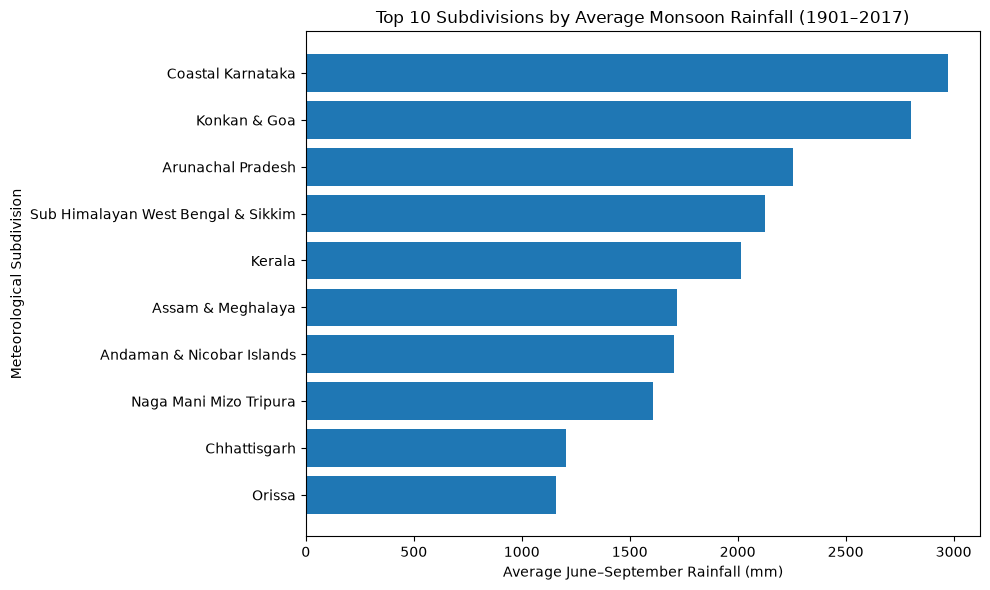

In [15]:
top_10 = monsoon_summary.head(10).sort_values("mean")

plt.figure(figsize=(10, 6))

plt.barh(top_10.index, top_10["mean"])

plt.title("Top 10 Subdivisions by Average Monsoon Rainfall (1901–2017)")
plt.xlabel("Average June–September Rainfall (mm)")
plt.ylabel("Meteorological Subdivision")

plt.tight_layout()
plt.savefig(
    "../images/top_10_monsoon_rainfall.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [20]:
annual_monsoon = (
    rainfall.groupby("YEAR")["JJAS"]
    .agg(["mean", "median", "std", "count"])
    .reset_index()
)

annual_monsoon.columns = [
    "YEAR",
    "mean_rainfall",
    "median_rainfall",
    "std_rainfall",
    "subdivisions_available"
]

display(annual_monsoon.head())
display(annual_monsoon.tail())
print("Minimum subdivisions available in a year:",
      annual_monsoon["subdivisions_available"].min())

print("Maximum subdivisions available in a year:",
      annual_monsoon["subdivisions_available"].max())

print("\nYears with fewer than 35 subdivisions:")
display(
    annual_monsoon[
        annual_monsoon["subdivisions_available"] < 35
    ]
)

,YEAR,mean_rainfall,median_rainfall,std_rainfall,subdivisions_available
0,1901,921.305714,700.9,653.026910,35
1,1902,1018.385714,811.2,762.621043,35
2,1903,1050.194286,866.8,639.341910,35
3,1904,933.874286,714.1,678.697194,35
4,1905,879.171429,805.4,608.763821,35


,YEAR,mean_rainfall,median_rainfall,std_rainfall,subdivisions_available
112,2013,1113.575000,938.35,764.519482,36
113,2014,941.572222,759.10,688.348720,36
114,2015,903.008333,743.70,563.304336,36
115,2016,1005.025000,862.35,648.748356,36
116,2017,1023.086111,766.90,650.111409,36


Minimum subdivisions available in a year: 34
Maximum subdivisions available in a year: 36

Years with fewer than 35 subdivisions:


,YEAR,mean_rainfall,median_rainfall,std_rainfall,subdivisions_available
8,1909,1066.705882,815.85,613.18188,34


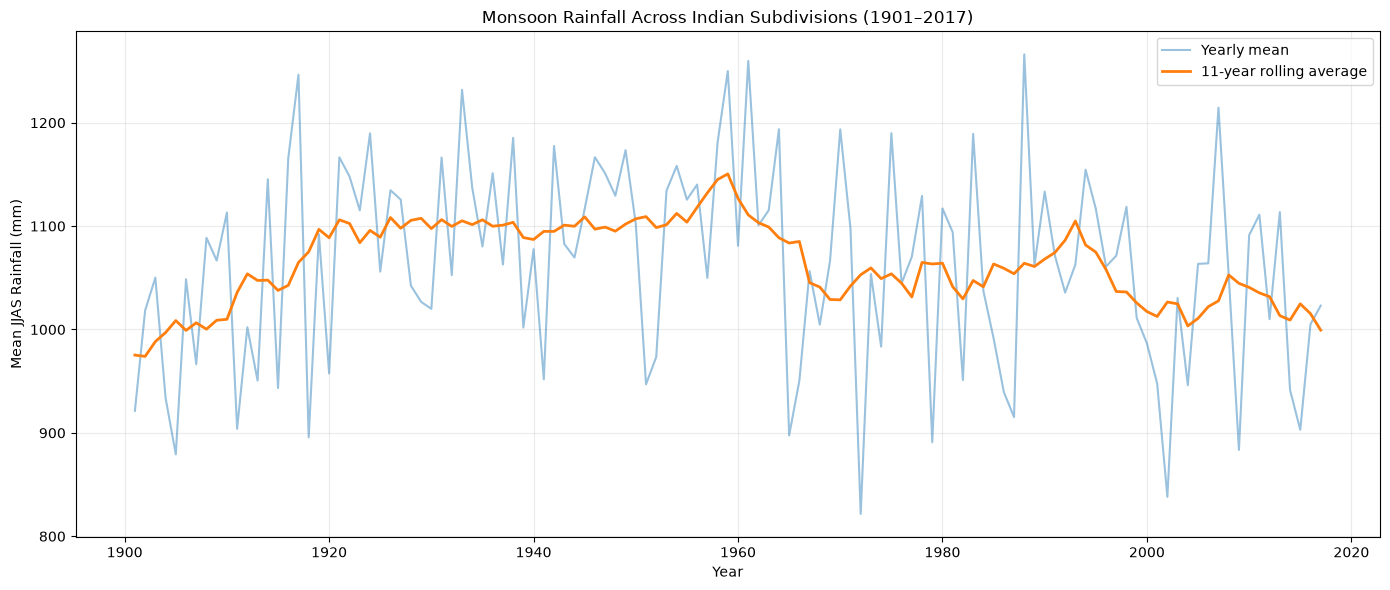

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    annual_monsoon["YEAR"],
    annual_monsoon["mean_rainfall"],
    alpha=0.45,
    label="Yearly mean"
)

plt.plot(
    annual_monsoon["YEAR"],
    annual_monsoon["mean_rainfall"].rolling(
        window=11, center=True, min_periods=6
    ).mean(),
    linewidth=2,
    label="11-year rolling average"
)

plt.title("Monsoon Rainfall Across Indian Subdivisions (1901–2017)")
plt.xlabel("Year")
plt.ylabel("Mean JJAS Rainfall (mm)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    "../images/monsoon_rainfall_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
# First and last 20-year periods compare karo
early = annual_monsoon[
    annual_monsoon["YEAR"].between(1901, 1920)
]

late = annual_monsoon[
    annual_monsoon["YEAR"].between(1998, 2017)
]

print("1901–1920 mean:", round(early["mean_rainfall"].mean(), 2), "mm")
print("1998–2017 mean:", round(late["mean_rainfall"].mean(), 2), "mm")

difference = late["mean_rainfall"].mean() - early["mean_rainfall"].mean()

print("Difference:", round(difference, 2), "mm")

1901–1920 mean: 1019.45 mm
1998–2017 mean: 1017.75 mm
Difference: -1.7 mm


In [22]:
months = [
    "JAN", "FEB", "MAR", "APR", "MAY", "JUN",
    "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"
]

monthly_summary = rainfall[months].mean()

print("Average rainfall by month (mm):")
display(monthly_summary.round(2))

Average rainfall by month (mm):


JAN     18.94
FEB     21.60
MAR     27.41
APR     43.07
MAY     85.66
JUN    230.12
JUL    347.02
AUG    289.74
SEP    197.32
OCT     95.32
NOV     39.50
DEC     18.97
dtype: float64

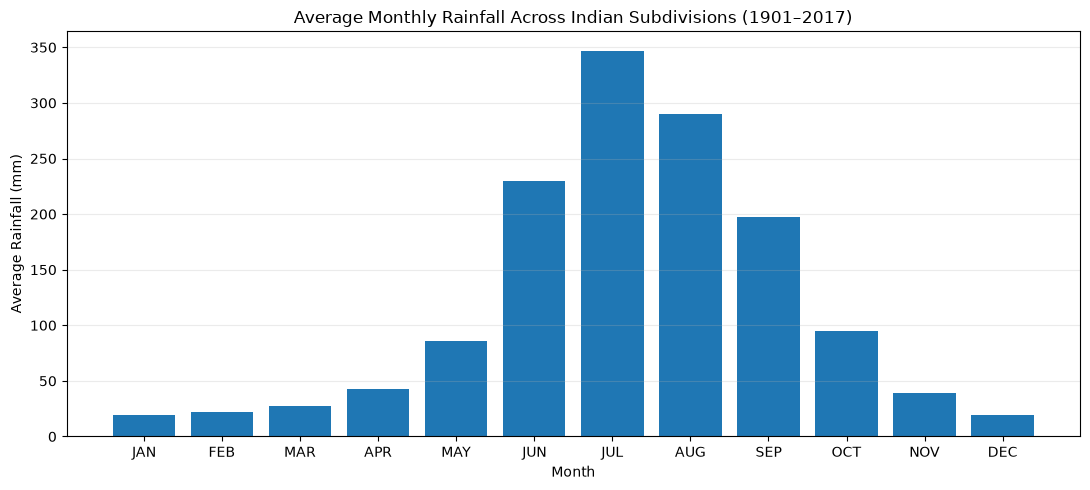

In [23]:
plt.figure(figsize=(11, 5))

plt.bar(monthly_summary.index, monthly_summary.values)

plt.title("Average Monthly Rainfall Across Indian Subdivisions (1901–2017)")
plt.xlabel("Month")
plt.ylabel("Average Rainfall (mm)")
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    "../images/monthly_rainfall_seasonality.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [24]:
wettest_years = (
    annual_monsoon
    .sort_values("mean_rainfall", ascending=False)
    .head(10)
)

display(wettest_years)

,YEAR,mean_rainfall,median_rainfall,std_rainfall,subdivisions_available
87,1988,1266.152778,1075.45,702.664408,36
60,1961,1259.719444,973.50,893.964238,36
58,1959,1249.963889,1063.15,834.597094,36
16,1917,1246.462857,1114.30,649.638020,35
32,1933,1231.838889,1088.80,727.405338,36
106,2007,1214.550000,975.80,809.529322,36
63,1964,1193.675000,956.90,789.296433,36
69,1970,1193.586111,996.40,787.700354,36
74,1975,1189.869444,1071.75,736.365680,36
23,1924,1189.658333,931.45,836.262559,36


In [25]:
driest_years = (
    annual_monsoon
    .sort_values("mean_rainfall", ascending=True)
    .head(10)
)

display(driest_years)

,YEAR,mean_rainfall,median_rainfall,std_rainfall,subdivisions_available
71,1972,821.583333,615.45,551.795197,36
101,2002,838.141667,645.20,586.349196,36
4,1905,879.171429,805.40,608.763821,35
108,2009,883.540000,689.40,633.278309,35
78,1979,890.897222,770.80,578.493358,36
17,1918,895.668571,566.60,863.872093,35
64,1965,897.530556,669.90,656.881422,36
114,2015,903.008333,743.70,563.304336,36
10,1911,903.948571,639.50,634.380980,35
86,1987,915.250000,650.95,728.103328,36


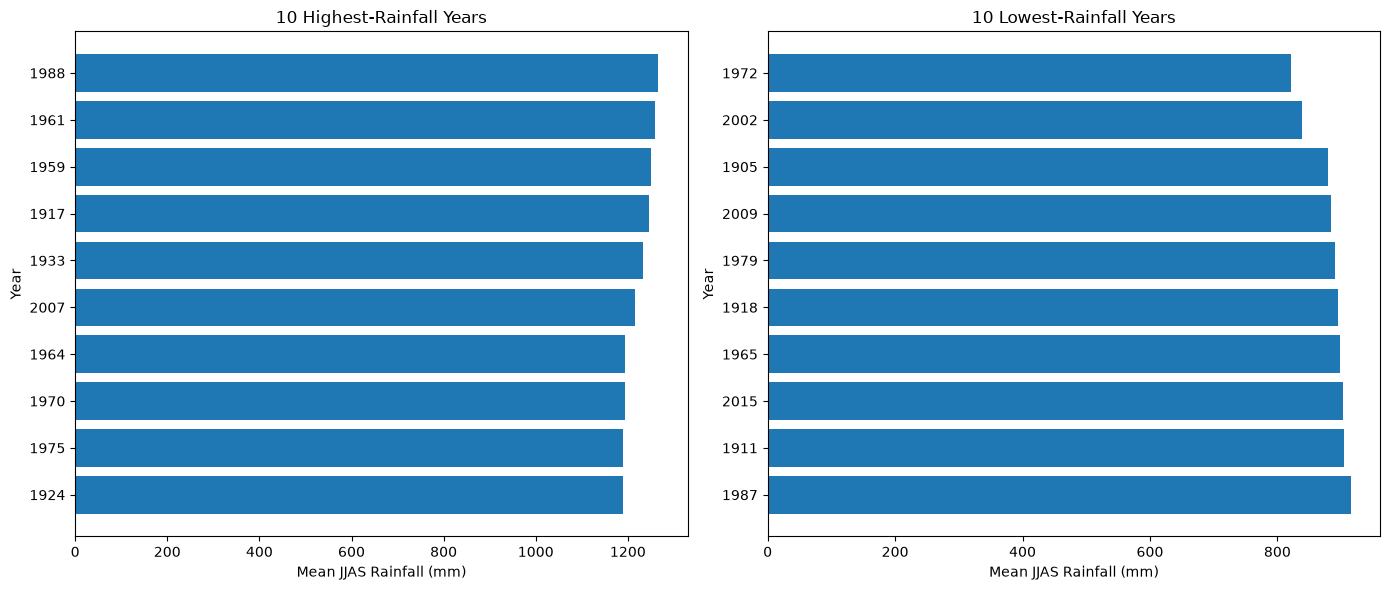

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(
    wettest_years["YEAR"].astype(str),
    wettest_years["mean_rainfall"]
)
axes[0].set_title("10 Highest-Rainfall Years")
axes[0].set_xlabel("Mean JJAS Rainfall (mm)")
axes[0].set_ylabel("Year")
axes[0].invert_yaxis()

axes[1].barh(
    driest_years["YEAR"].astype(str),
    driest_years["mean_rainfall"]
)
axes[1].set_title("10 Lowest-Rainfall Years")
axes[1].set_xlabel("Mean JJAS Rainfall (mm)")
axes[1].set_ylabel("Year")
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig(
    "../images/wettest_driest_monsoon_years.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [28]:
print("Wettest years: available subdivisions")
display(wettest_years[["YEAR", "mean_rainfall", "subdivisions_available"]])

print("Driest years: available subdivisions")
display(driest_years[["YEAR", "mean_rainfall", "subdivisions_available"]])

Wettest years: available subdivisions


,YEAR,mean_rainfall,subdivisions_available
87,1988,1266.152778,36
60,1961,1259.719444,36
58,1959,1249.963889,36
16,1917,1246.462857,35
32,1933,1231.838889,36
106,2007,1214.550000,36
63,1964,1193.675000,36
69,1970,1193.586111,36
74,1975,1189.869444,36
23,1924,1189.658333,36


Driest years: available subdivisions


,YEAR,mean_rainfall,subdivisions_available
71,1972,821.583333,36
101,2002,838.141667,36
4,1905,879.171429,35
108,2009,883.540000,35
78,1979,890.897222,36
17,1918,895.668571,35
64,1965,897.530556,36
114,2015,903.008333,36
10,1911,903.948571,35
86,1987,915.250000,36


\[
CV = \frac{\text{Standard Deviation}}{\text{Mean}} \times 100
\]

In [29]:
variability = (
    rainfall.groupby("SUBDIVISION")["JJAS"]
    .agg(["count", "mean", "std"])
    .reset_index()
)

variability["CV_percent"] = (
    variability["std"] / variability["mean"]
) * 100

variability = variability.round(2)

display(
    variability.sort_values(
        "CV_percent",
        ascending=False
    ).head(10)
)

,SUBDIVISION,count,mean,std,CV_percent
26,Saurashtra & Kutch,117,464.70,194.92,41.95
34,West Rajasthan,117,260.11,101.30,38.95
1,Arunachal Pradesh,97,2258.21,826.44,36.60
24,Punjab,117,459.00,149.66,32.61
11,Gujarat Region,117,877.72,271.82,30.97
12,Haryana Delhi & Chandigarh,117,436.31,134.54,30.84
14,Jammu & Kashmir,116,515.39,150.14,29.13
13,Himachal Pradesh,117,773.86,205.21,26.52
8,East Rajasthan,117,604.49,156.56,25.90
20,Matathwada,117,663.78,168.68,25.41


In [30]:
stable_regions = variability.sort_values(
    "CV_percent",
    ascending=True
).head(10)

display(stable_regions)

,SUBDIVISION,count,mean,std,CV_percent
23,Orissa,117,1156.83,151.47,13.09
2,Assam & Meghalaya,117,1717.39,226.87,13.21
28,Sub Himalayan West Bengal & Sikkim,117,2124.70,295.00,13.88
4,Chhattisgarh,117,1202.88,176.89,14.71
6,Coastal Karnataka,117,2973.53,455.95,15.33
15,Jharkhand,117,1083.88,166.89,15.40
10,Gangetic West Bengal,117,1130.96,184.47,16.31
17,Konkan & Goa,117,2804.19,459.32,16.38
0,Andaman & Nicobar Islands,109,1703.71,286.36,16.81
3,Bihar,117,1014.92,175.14,17.26


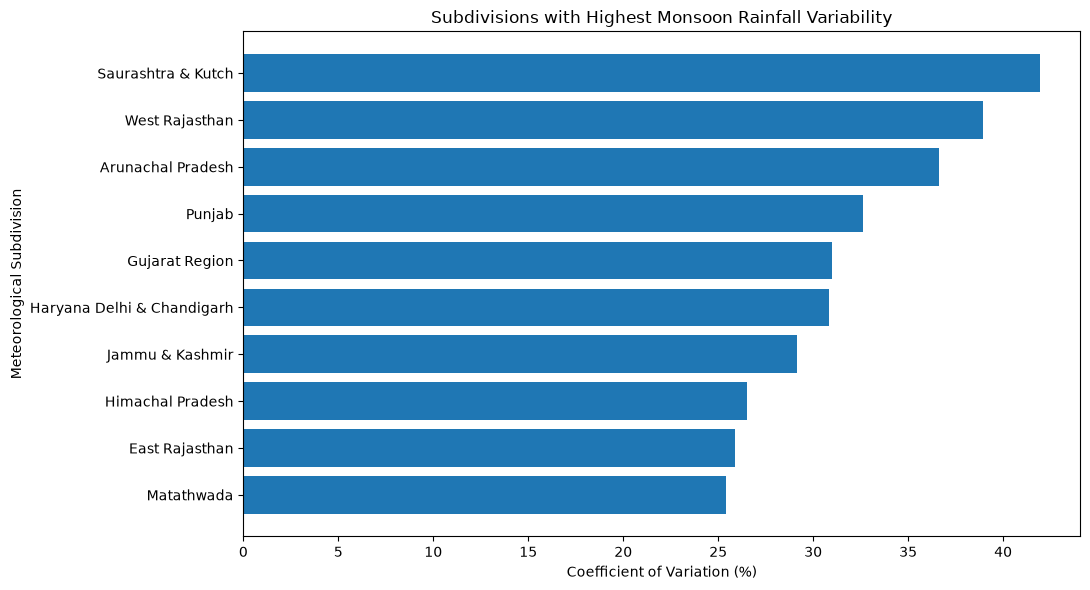

In [31]:
top_variable = variability.sort_values(
    "CV_percent",
    ascending=False
).head(10).sort_values("CV_percent")

plt.figure(figsize=(11, 6))

plt.barh(
    top_variable["SUBDIVISION"],
    top_variable["CV_percent"]
)

plt.title("Subdivisions with Highest Monsoon Rainfall Variability")
plt.xlabel("Coefficient of Variation (%)")
plt.ylabel("Meteorological Subdivision")

plt.tight_layout()

plt.savefig(
    "../images/monsoon_rainfall_variability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
# Save key summary tables

monsoon_summary.to_csv(
    "../data/processed/subdivision_monsoon_summary.csv"
)

annual_monsoon.to_csv(
    "../data/processed/annual_monsoon_summary.csv",
    index=False
)

variability.to_csv(
    "../data/processed/subdivision_rainfall_variability.csv",
    index=False
)

monthly_summary.to_csv(
    "../data/processed/monthly_rainfall_summary.csv"
)

print("Rainfall summary tables saved successfully!")

Rainfall summary tables saved successfully!
